In [7]:
import plotly.io as pio
pio.renderers.default = "notebook_connected"

In [8]:
import pandas as pd

df = pd.read_csv("files/processed_posts_dedup.csv")

print(df.shape)                      # expect (1058, 15)
print(df.dtypes)
print(df.isna().sum())

df["created_at"] = pd.to_datetime(df["created_at"], errors="coerce")
print(df["created_at"].min(), df["created_at"].max())   # expect within 14-21 Sep 2026
print(df["created_at"].isna().sum())                    # expect 0

print(df["country"].nunique())       # expect 75 or 76
print(df["country"].value_counts().head(10))

(1058, 17)
id                    int64
created_at           object
full_text            object
screen_name          object
name                 object
profile_location     object
country              object
hashtags             object
favorite_count        int64
retweet_count         int64
bookmark_count        int64
quote_count           int64
reply_count           int64
views_count         float64
url                  object
tokens               object
tokens_str           object
dtype: object
id                  0
created_at          0
full_text           0
screen_name         0
name                0
profile_location    0
country             0
hashtags            0
favorite_count      0
retweet_count       0
bookmark_count      0
quote_count         0
reply_count         0
views_count         0
url                 0
tokens              0
tokens_str          0
dtype: int64
2026-09-14 12:08:31+05:00 2026-09-21 23:47:35+05:00
0
76
country
United States     408
United Kingdom    147
Can

In [9]:
import json
import pandas as pd
import plotly.express as px

with open("data/freq_overall.json") as f:
    freq = json.load(f)

print(type(freq))
print(list(freq.items())[:5] if isinstance(freq, dict) else freq[:5])

<class 'list'>
[['west', 1242], ['bank', 1221], ['israel', 955], ['israeli', 712], ['gaza', 650]]


In [10]:
if isinstance(freq, dict):
    terms_df = pd.DataFrame(list(freq.items()), columns=["term", "count"])
else:
    terms_df = pd.DataFrame(freq, columns=["term", "count"])

top = terms_df.sort_values("count", ascending=False).head(20)
print(top)

fig = px.bar(
    top.sort_values("count"),
    x="count", y="term", orientation="h",
    title="Top 20 terms in the sample (profile-based country sample, 14-21 Sep 2026)",
    labels={"count": "Occurrences", "term": ""},
    color_discrete_sequence=["#333333"],
)
fig.update_layout(plot_bgcolor="white")
fig.show()

            term  count
0           west   1242
1           bank   1221
2         israel    955
3        israeli    712
4           gaza    650
5    palestinian    580
6         people    374
7   palestinians    305
8            war    276
9            one    276
10         state    275
11        jewish    265
12     palestine    265
13          said    254
14      occupied    242
15         world    232
16         hamas    227
17          also    222
18         would    207
19           god    194


In [11]:
df = pd.read_csv("files/processed_posts_dedup.csv")
mask = df["full_text"].str.contains(r"\bgod\b", case=False, regex=True)

print(mask.sum(), "posts,", df.loc[mask, "screen_name"].nunique(), "authors")
print(df.loc[mask, "country"].value_counts().head())
print(df.loc[mask, "screen_name"].value_counts().head())
print(df.loc[mask, "full_text"].str[:80].value_counts().head(5))

19 posts, 14 authors
country
United States     12
South Korea        3
United Kingdom     2
Kenya              1
Albania            1
Name: count, dtype: int64
screen_name
TrueNewsSaini     3
charcochoe2025    3
MtnShepherdess    2
CathChurchLove    1
CarolEttaKelso    1
Name: count, dtype: int64
full_text
WARNING TO PRESIDENT ERDOGAN AND AYATOLLAH MOJTABA KHAMENEI (AMK) AND THE PURPOS    2
@SenateDems @AlexPadilla4CA @SenAdamSchiff @BernieSanders @SenDuckworth @SenMark    1
Please God saves these resistance fighters in West Bank who kidnapped by Israeli    1
Please God saves this resistance fighter in West Bank who fights against Israel.    1
Netanyahu, Israel and the Dragon of Endless Middle East War and a Region in Flam    1
Name: count, dtype: int64


In [12]:
df["god_n"] = df["full_text"].str.count(r"(?i)\bgod\b")

print(df.loc[mask, "god_n"].sum())          # roughly 190 expected
print(df.loc[mask].sort_values("god_n", ascending=False)[["screen_name", "country", "god_n"]].head(5))

183
        screen_name        country  god_n
11    TrueNewsSaini  United States     55
14    TrueNewsSaini  United States     55
858   TrueNewsSaini  United States     46
240  MtnShepherdess  United States      8
131  CathChurchLove  United States      3


In [13]:
from collections import Counter
import pandas as pd

df = pd.read_csv("files/processed_posts_dedup.csv")
print(df["tokens_str"].iloc[0][:100])      # expect space-separated tokens

occ, docs = Counter(), Counter()
for s in df["tokens_str"].fillna(""):
    toks = s.split()
    occ.update(toks)
    docs.update(set(toks))

terms = pd.DataFrame({"term": list(occ), "occurrences": list(occ.values())})
terms["posts"] = terms["term"].map(docs)
terms["pct_posts"] = (terms["posts"] / len(df) * 100).round(1)

QUERY_TERMS = {"west", "bank", "gaza", "palestinian", "palestinians", "palestine"}
terms["is_query_term"] = terms["term"].isin(QUERY_TERMS)

print(terms.sort_values("posts", ascending=False).head(20))
print(terms[terms["term"] == "god"])

terms.sort_values("posts", ascending=False).head(100).to_csv("data/terms_overall.csv", index=False)

know never hamas proof none started never gaza always whole opt hebron west bank
              term  occurrences  posts  pct_posts  is_query_term
12            bank         1208   1056       99.8           True
11            west         1229   1055       99.7           True
6             gaza          630    410       38.8           True
74         israeli          712    403       38.1          False
42          israel          935    385       36.4          False
117    palestinian          579    321       30.3           True
1140      occupied          242    212       20.0          False
168   palestinians          305    208       19.7           True
35          people          366    169       16.0          False
1136     palestine          261    158       14.9           True
30             one          273    153       14.5          False
83           state          274    136       12.9          False
16             war          273    124       11.7          False
20       

In [14]:
import plotly.express as px

top = (terms[~terms["is_query_term"]]
       .sort_values("posts", ascending=False).head(20))

fig = px.bar(
    top.sort_values("posts"),
    x="posts", y="term", orientation="h",
    title="Top 20 terms by number of posts containing them (search terms hidden)",
    labels={"posts": "Posts containing the term", "term": ""},
    color_discrete_sequence=["#333333"],
)
fig.update_layout(plot_bgcolor="white")
fig.show()

In [15]:
df = pd.read_csv("files/processed_posts_dedup.csv")
wb = df["full_text"].str.contains(r"west(?:\s|\\n)+bank", case=False, regex=True)
print(wb.sum(), "of", len(df), f"({wb.mean():.1%}) contain the phrase 'west bank'")
print(df.loc[~wb, ["country", "full_text"]].head(10))

1054 of 1058 (99.6%) contain the phrase 'west bank'
            country                                          full_text
149   United States  🚨 TDFP News Roundup – 9/20/26 🚨\n\n𝗧𝗿𝘂𝗺𝗽 𝘄𝗮𝗿𝗻𝘀...
244  United Kingdom  🟥 UPDATE NUMBER TWO | 20 SEPTEMBER 2026\n▪️Jou...
715   United States  Bet El checkpoint this morning 👇\n\nEnough wit...
746           Egypt  The Muslim Brotherhood wrote the plan in 1991....


In [16]:
raw = pd.read_csv("files/batch-3.csv")
t = raw["full_text"].fillna("").str.lower()

wb = t.str.contains(r"west(?:\s|\\n)+bank", regex=True)
gaza = t.str.contains("gaza")
pal = t.str.contains("palestin")

print(len(raw), "raw posts")
print("contain 'west bank':", wb.sum())
print("gaza without 'west bank':", (gaza & ~wb).sum())
print("palestin* without 'west bank':", (pal & ~wb).sum())

3326 raw posts
contain 'west bank': 2824
gaza without 'west bank': 3
palestin* without 'west bank': 5


In [17]:
import pandas as pd
from collections import Counter, defaultdict

df = pd.read_csv("files/processed_posts_dedup.csv")
counts = df["country"].value_counts()
ELIGIBLE = counts[counts >= 20].index.tolist()
QUERY_TERMS = {"west", "bank", "gaza", "palestinian", "palestinians", "palestine"}

rows = []
for c in ELIGIBLE:
    sub = df[df["country"] == c]
    post_ct = Counter()
    author_sets = defaultdict(set)
    for tokens, author in zip(sub["tokens_str"].fillna(""), sub["screen_name"]):
        for t in set(tokens.split()):
            post_ct[t] += 1
            author_sets[t].add(author)
    for t, n in post_ct.items():
        rows.append((c, t, n, len(author_sets[t]), len(sub)))

tc = pd.DataFrame(rows, columns=["country", "term", "posts", "authors", "n_country_posts"])
tc["pct_posts"] = (tc["posts"] / tc["n_country_posts"] * 100).round(1)
tc = tc[~tc["term"].isin(QUERY_TERMS)]

top = (tc.sort_values(["country", "posts", "authors"], ascending=[True, False, False])
         .groupby("country").head(10))
print(ELIGIBLE)
print(top.to_string(index=False))

top.to_csv("data/terms_by_country.csv", index=False)

['United States', 'United Kingdom', 'Canada', 'Australia', 'Israel', 'India', 'Philippines', 'Ireland']
       country          term  posts  authors  n_country_posts  pct_posts
     Australia        israel     23       20               46       50.0
     Australia       israeli     17       14               46       37.0
     Australia          even     10        8               46       21.7
     Australia     australia      8        7               46       17.4
     Australia international      8        6               46       17.4
     Australia           one      8        6               46       17.4
     Australia        people      8        5               46       17.4
     Australia      military      8        5               46       17.4
     Australia         would      7        7               46       15.2
     Australia      settlers      7        6               46       15.2
        Canada        israel     25       23               60       41.7
        Canada      

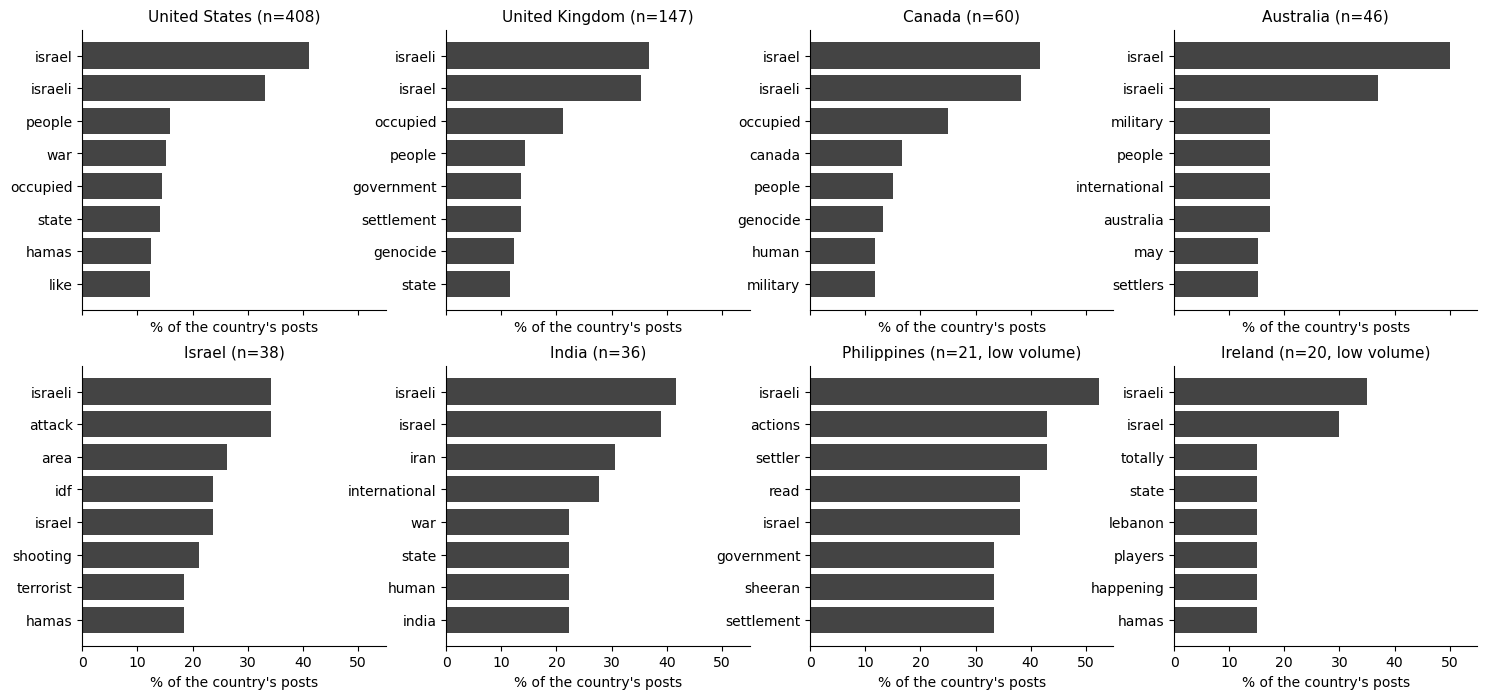

In [20]:
DISPLAY_FILLER = {"one", "also", "would", "even", "still", "said", "like", "may"}
# ...same filtering code as before...

fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharex=True)
for ax, c in zip(axes.flat, order):
    d = top[top["country"] == c].sort_values("pct_posts")
    n = d["n_country_posts"].iloc[0]
    ax.barh(d["term"], d["pct_posts"], color="#444444")
    ax.set_title(f"{c} (n={n}{', low volume' if n < 30 else ''})", fontsize=11)
    ax.set_xlabel("% of the country's posts")
    ax.spines[["top", "right"]].set_visible(False)

In [21]:
df = pd.read_csv("files/processed_posts_dedup.csv")
print(df["hashtags"].head(10).tolist())
print(type(df["hashtags"].iloc[0]))
print(df["hashtags"].value_counts().head(5))

['[]', '[]', '[]', '[]', '[]', '[]', '[]', '[]', '[]', "['Gravitas']"]
<class 'str'>
hashtags
[]                                  937
['Gaza']                              4
['ServiceAlert', 'TrentCentral']      3
['Palestine']                         2
['BREAKING']                          2
Name: count, dtype: int64


In [22]:
import ast
import pandas as pd
from collections import Counter, defaultdict

df = pd.read_csv("files/processed_posts_dedup.csv")
df["tags"] = df["hashtags"].apply(ast.literal_eval)

has = df["tags"].str.len() > 0
print(has.sum(), "of", len(df), f"({has.mean():.1%}) posts have at least one hashtag")

post_ct, auth = Counter(), defaultdict(set)
for tags, a in zip(df["tags"], df["screen_name"]):
    for t in {x.lower() for x in tags}:
        post_ct[t] += 1
        auth[t].add(a)

ht = pd.DataFrame({"hashtag": list(post_ct), "posts": list(post_ct.values())})
ht["authors"] = ht["hashtag"].map(lambda t: len(auth[t]))
ht = ht.sort_values(["posts", "authors"], ascending=False)

print(len(ht), "distinct hashtags")
print(ht.head(15).to_string(index=False))

121 of 1058 (11.4%) posts have at least one hashtag
292 distinct hashtags
        hashtag  posts  authors
       westbank     29       23
      palestine     25       20
         israel     24       21
           gaza     17       17
     middleeast      8        7
   breakingnews      7        6
  freepalestine      7        5
             un      6        4
           iran      5        4
   gazagenocide      5        3
            idf      4        4
      apartheid      4        2
            usa      4        2
ethniccleansing      4        2
       breaking      3        3


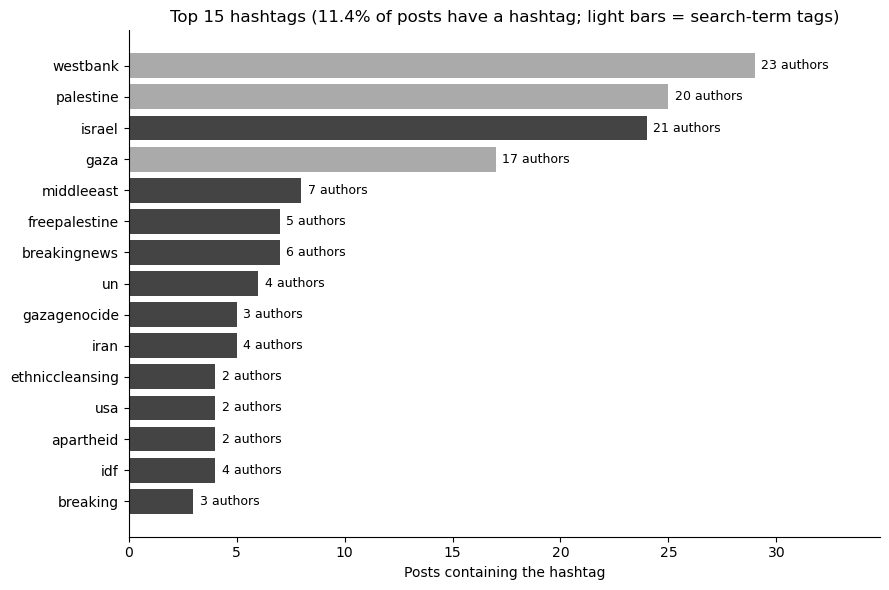

In [23]:
import matplotlib.pyplot as plt

QUERY_TAGS = {"westbank", "palestine", "gaza"}
top = ht.head(15).sort_values("posts")
colors = ["#AAAAAA" if h in QUERY_TAGS else "#444444" for h in top["hashtag"]]

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top["hashtag"], top["posts"], color=colors)
for y, (p, a) in enumerate(zip(top["posts"], top["authors"])):
    ax.text(p + 0.3, y, f"{a} authors", va="center", fontsize=9)
ax.set_xlim(0, top["posts"].max() * 1.2)
ax.set_xlabel("Posts containing the hashtag")
ax.set_title("Top 15 hashtags (11.4% of posts have a hashtag; light bars = search-term tags)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

ht["is_query_tag"] = ht["hashtag"].isin(QUERY_TAGS)
(ht.head(30)
   .assign(n_posts_total=len(df), n_posts_with_tag=int(has.sum()))
   .to_csv("data/hashtags_overall.csv", index=False))

In [24]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("files/processed_posts_dedup.csv")
df["created_utc"] = pd.to_datetime(df["created_at"], utc=True)

print(df["created_utc"].min(), df["created_utc"].max())

daily = (df.set_index("created_utc")
           .resample("D").size()
           .rename("posts").reset_index())
daily["date"] = daily["created_utc"].dt.date
daily["pct"] = (daily["posts"] / len(df) * 100).round(1)

print(daily[["date", "posts", "pct"]])
print(daily["posts"].sum())      # expect 1058

2026-09-14 07:08:31+00:00 2026-09-21 18:47:35+00:00
         date  posts   pct
0  2026-09-14      6   0.6
1  2026-09-15      8   0.8
2  2026-09-16     58   5.5
3  2026-09-17    221  20.9
4  2026-09-18    179  16.9
5  2026-09-19    137  12.9
6  2026-09-20    310  29.3
7  2026-09-21    139  13.1
1058


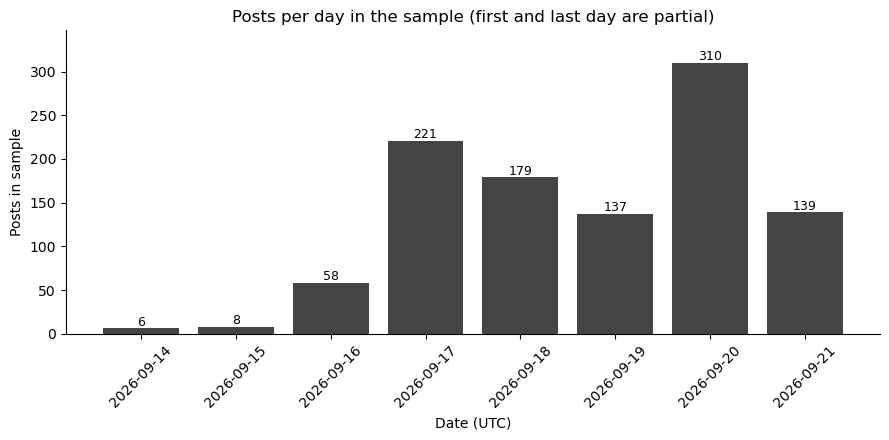

In [25]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(daily["date"].astype(str), daily["posts"], color="#444444")
for i, p in enumerate(daily["posts"]):
    ax.text(i, p + daily["posts"].max() * 0.01, str(p), ha="center", fontsize=9)
ax.set_ylim(0, daily["posts"].max() * 1.12)
ax.set_ylabel("Posts in sample")
ax.set_xlabel("Date (UTC)")
ax.set_title("Posts per day in the sample (first and last day are partial)")
ax.spines[["top", "right"]].set_visible(False)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

daily[["date", "posts"]].to_csv("data/posts_per_day.csv", index=False)

In [26]:
df["date"] = df["created_utc"].dt.date
counts = df["country"].value_counts()
eligible = counts[counts >= 20].index

ct = (pd.crosstab(df.loc[df["country"].isin(eligible), "country"],
                  df.loc[df["country"].isin(eligible), "date"],
                  normalize="index").mul(100).round(0))
print(ct)

date            2026-09-14  2026-09-15  2026-09-16  2026-09-17  2026-09-18  \
country                                                                      
Australia              2.0         0.0         7.0        11.0        15.0   
Canada                 0.0         0.0         3.0        28.0        22.0   
India                  0.0         0.0         6.0        22.0        25.0   
Ireland                0.0         0.0         0.0        50.0         5.0   
Israel                 0.0         0.0         5.0        18.0        11.0   
Philippines            0.0         0.0         0.0        33.0        10.0   
United Kingdom         1.0         2.0         4.0        24.0        15.0   
United States          0.0         1.0         7.0        20.0        18.0   

date            2026-09-19  2026-09-20  2026-09-21  
country                                             
Australia             24.0        17.0        24.0  
Canada                10.0        27.0        10.0  
India  

In [27]:
v = df["views_count"].sort_values(ascending=False)
print("top 10 posts share of all views:", round(v.head(10).sum() / v.sum() * 100, 1), "%")
print("top 1% share:", round(v.head(int(len(v) * 0.01)).sum() / v.sum() * 100, 1), "%")
print(v.describe())

top 10 posts share of all views: 40.3 %
top 1% share: 40.3 %
count      1058.000000
mean       4028.034972
std       20694.407495
min           1.000000
25%          34.000000
50%         138.500000
75%         834.250000
max      400404.000000
Name: views_count, dtype: float64


In [28]:
isr = df[df["country"] == "Israel"]
on20 = isr["date"].astype(str) == "2026-09-20"
for t in ["attack", "shooting", "idf", "area"]:
    m = isr["tokens_str"].str.split().apply(lambda x: t in x)
    print(t, "posts:", m.sum(), "| on 20 Sep:", (m & on20).sum())

attack posts: 13 | on 20 Sep: 12
shooting posts: 8 | on 20 Sep: 8
idf posts: 9 | on 20 Sep: 6
area posts: 10 | on 20 Sep: 6


In [29]:
ct_out = ct.copy()
ct_out["n_posts"] = counts[ct_out.index].values
ct_out.reset_index().to_csv("data/country_by_day_pct.csv", index=False)

                country  posts                 group   pct
0         United States    408  Eligible (≥20 posts)  38.6
1        United Kingdom    147  Eligible (≥20 posts)  13.9
2                Canada     60  Eligible (≥20 posts)   5.7
3             Australia     46  Eligible (≥20 posts)   4.3
4                Israel     38  Eligible (≥20 posts)   3.6
5                 India     36  Eligible (≥20 posts)   3.4
6           Philippines     21  Eligible (≥20 posts)   2.0
7               Ireland     20  Eligible (≥20 posts)   1.9
8  Other (68 countries)    282                 Other  26.7
1058


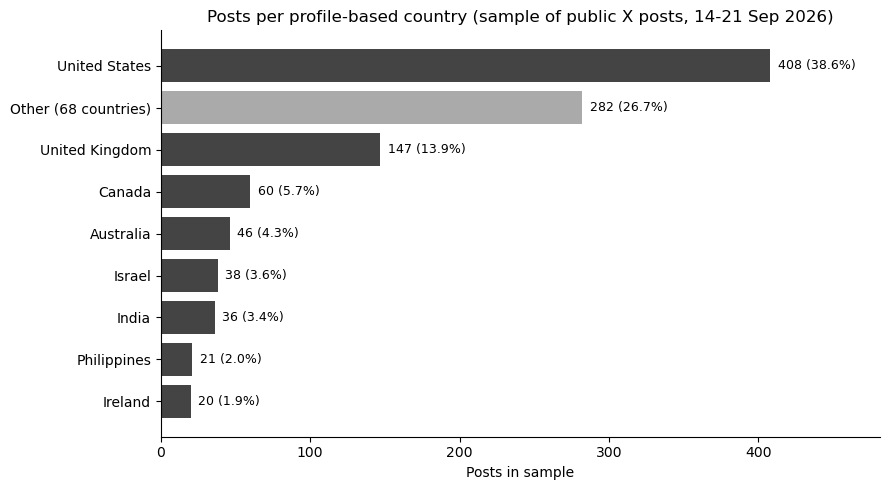

In [31]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("files/processed_posts_dedup.csv")
MIN_POSTS = 20
counts = df["country"].value_counts()

eligible = counts[counts >= MIN_POSTS]
other_total = int(counts[counts < MIN_POSTS].sum())
other_n = int((counts < MIN_POSTS).sum())

plot_df = eligible.rename_axis("country").reset_index(name="posts")
plot_df["group"] = "Eligible (≥20 posts)"
plot_df.loc[len(plot_df)] = [f"Other ({other_n} countries)", other_total, "Other"]
plot_df["pct"] = (plot_df["posts"] / len(df) * 100).round(1)

print(plot_df)
print(plot_df["posts"].sum())          # expect 1058

d = plot_df.sort_values("posts")
colors = ["#AAAAAA" if g == "Other" else "#444444" for g in d["group"]]

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(d["country"], d["posts"], color=colors)
for y, (p, pc) in enumerate(zip(d["posts"], d["pct"])):
    ax.text(p + 5, y, f"{p} ({pc}%)", va="center", fontsize=9)
ax.set_xlim(0, d["posts"].max() * 1.18)
ax.set_xlabel("Posts in sample")
ax.set_title("Posts per profile-based country (sample of public X posts, 14-21 Sep 2026)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

plot_df.to_csv("data/country_counts.csv", index=False)

In [32]:
import os
print(sorted(os.listdir("data")))

['country_by_day_pct.csv', 'country_counts.csv', 'freq_by_country.json', 'freq_overall.json', 'hashtags_overall.csv', 'pmi_results.json', 'posts_per_day.csv', 'terms_by_country.csv', 'terms_overall.csv']


In [33]:
terms[terms["posts"] >= 10].sort_values("posts", ascending=False).to_csv("data/terms_overall.csv", index=False)

In [38]:
import json, pandas as pd
df = pd.read_csv("files/processed_posts_dedup.csv")
toks = df["tokens_str"].str.split().apply(set)
pmi = json.load(open("data/pmi_results.json"))
rows = []
for (a, b), s in pmi:
    m = toks.apply(lambda t: a in t and b in t)
    rows.append((a, b, round(s, 2), m.sum(), df.loc[m, "screen_name"].nunique()))
print(pd.DataFrame(rows, columns=["w1","w2","pmi","posts","authors"]))

                  w1                w2   pmi  posts  authors
0               gvir            itamar  6.05     10       10
1             hormuz            strait  6.02     12       10
2             drones          missiles  5.91     10        8
3                ben              gvir  5.80     16       14
4                ben            itamar  5.80     10       10
5   disproportionate     unjustifiable  5.79     11       11
6             lineup            rapper  5.73     10        7
7              drone           missile  5.46     12       10
8       catastrophic     unjustifiable  5.38     13       13
9           horrific     unjustifiable  5.37     10       10
10      catastrophic  disproportionate  5.37     12       12
11            kippur               yom  5.29     27       24
12      philadelphia     unjustifiable  5.21     10       10
13            arabia            riyadh  5.21     10        8
14             drone          missiles  5.20     10        8
15             kraft    

In [39]:
m = df["tokens_str"].str.split().apply(lambda t: {"unjustifiable","catastrophic"} <= set(t))
print(m.sum(), df.loc[m, "screen_name"].nunique())
for t in df.loc[m, "full_text"].head(5):
    print("-", t[:220].replace("\n", " "))

13 13
- "Ed Sheeran condemned the Oct. 7, 2023 Hamas-led attacks in Israel, while describing the continuing situation in Gaza as “catastrophic and unjustifiable and disproportionate.” He also referenced civilian deaths and condi
- Ed Sheeran walked onstage in Philadelphia Saturday night looking like a man who hadn’t slept in a week and then opened his first show since the Macklemore fallout by saying the quiet part out loud.\n\n“I’ve had to take a
- 🚨 Ed Sheeran finally speaks out on Israel and Gaza! 😳\n\nAs he resumed his U.S. tour in Philadelphia, Ed Sheeran addressed the recent controversy and apologized for what he called his “mistakes.”\n\nHe said he has always
- Ed Sheeran apologized for his handling of Macklemore’s removal from his US tour, telling fans in Philadelphia that he had made mistakes and was “so, so sorry.”\n\nSheeran called the October 7 Hamas attack “horrific,” whi
- Ed Sheeran addressed the Macklemore controversy during an emotional speech at his Saturday night con